Day 3 — Build a Neural Network Training Loop from Scratch

**Goal:** Understand and implement the core training loop for a small multilayer perceptron (MLP) using PyTorch, then train it on FashionMNIST.

By the end, you should be able to explain:
- how a batch moves through a model (`forward pass`)
- how predictions are compared with labels (`loss`)
- how gradients are calculated (`backpropagation`)
- how model parameters are updated (`optimizer step`)
- how to evaluate a model on unseen test data

**Important:** This notebook trains a small model from scratch. It does not use a pretrained model.

The training loop

For each batch of training examples, the loop does the following:

1. **Forward pass:** `model(images)` produces predictions.
2. **Calculate loss:** compare predictions with the correct labels.
3. **Clear old gradients:** `optimizer.zero_grad()`.
4. **Backpropagation:** `loss.backward()` computes gradients.
5. **Update parameters:** `optimizer.step()` uses those gradients to update weights.

One epoch means one complete pass through the training dataset. We evaluate on test data separately and do not use test results to update the model.

In [1]:
# 1. Imports and reproducibility
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cpu
Device: cpu


2. Load FashionMNIST

FashionMNIST contains 28 × 28 grayscale images in 10 clothing categories. `ToTensor()` converts each image to a tensor and scales pixel values to the range 0–1.

The training set is used to learn parameters. The test set is reserved for final evaluation.

In [2]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)
test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

BATCH_SIZE = 64
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training examples:", len(train_data))
print("Test examples:", len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 22.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 346kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.21MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.45MB/s]


Training examples: 60000
Test examples: 10000


Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])
Pixel range: 0.0 to 1.0


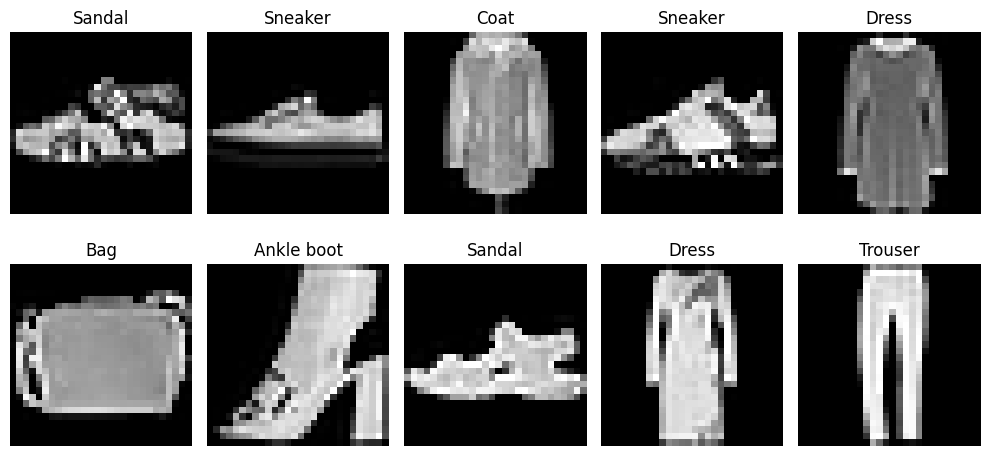

In [3]:
# Inspect one batch
images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)  # [batch, channels, height, width]
print("Batch label shape:", labels.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

3. Define an MLP

Each 28 × 28 image has 784 pixels. We flatten the image into a vector, then pass it through two fully connected layers:
- `784 → 128` hidden units with ReLU
- `128 → 10` output scores (one per class)

The final layer returns **logits** (raw scores). Do not apply softmax before `CrossEntropyLoss`; that loss function expects logits.

In [4]:
class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)

model = FashionMLP().to(device)
print(model)

# Number of trainable parameters
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", num_params)

FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 101770


4. Loss function and optimizer

- **Loss:** `nn.CrossEntropyLoss()` measures how well the predicted class scores match the correct labels.
- **Optimizer:** `torch.optim.SGD` updates the model's parameters using gradients.
- **Learning rate:** controls the size of each update. Too large can make training unstable; too small can make it slow.

The next cell defines a training function that implements the five training-loop steps.

In [5]:
loss_fn = nn.CrossEntropyLoss()
LEARNING_RATE = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()  # training mode
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        # 1. Forward pass
        logits = model(batch_images)

        # 2. Calculate loss
        loss = loss_fn(logits, batch_labels)

        # 3. Clear gradients from the previous batch
        optimizer.zero_grad()

        # 4. Backpropagation: calculate gradients
        loss.backward()

        # 5. Update model parameters
        optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        predictions = logits.argmax(dim=1)
        total_correct += (predictions == batch_labels).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples

5. Evaluate the model

During evaluation, gradients are not needed, so we use `torch.no_grad()`. `model.eval()` switches the model into evaluation mode. This MLP has no dropout or batch normalization, but using evaluation mode is good practice.

calculate average loss and accuracy across the whole evaluation dataset.

In [6]:
def evaluate(model, data_loader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            logits = model(batch_images)
            loss = loss_fn(logits, batch_labels)

            batch_size = batch_labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
            total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples

6. Train the model

We will train for 5 epochs to keep this exercise manageable. Training time depends on whether Colab assigns a GPU. Watch training loss and accuracy as they change.

The test set is evaluated after each epoch for learning purposes. In a larger project, you would typically use a separate validation set for tuning and reserve the test set for final evaluation.

In [7]:
EPOCHS = 5
history = {"train_loss": [], "train_accuracy": [], "test_loss": [], "test_accuracy": []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )
    test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train loss: {train_loss:.4f} | train accuracy: {train_acc:.2%} | "
        f"test loss: {test_loss:.4f} | test accuracy: {test_acc:.2%}"
    )

Epoch 1/5 | train loss: 0.6259 | train accuracy: 77.91% | test loss: 0.4950 | test accuracy: 82.42%
Epoch 2/5 | train loss: 0.4419 | train accuracy: 84.11% | test loss: 0.5741 | test accuracy: 80.04%
Epoch 3/5 | train loss: 0.3970 | train accuracy: 85.82% | test loss: 0.4706 | test accuracy: 82.84%
Epoch 4/5 | train loss: 0.3703 | train accuracy: 86.59% | test loss: 0.3890 | test accuracy: 86.32%
Epoch 5/5 | train loss: 0.3527 | train accuracy: 87.37% | test loss: 0.4397 | test accuracy: 84.53%


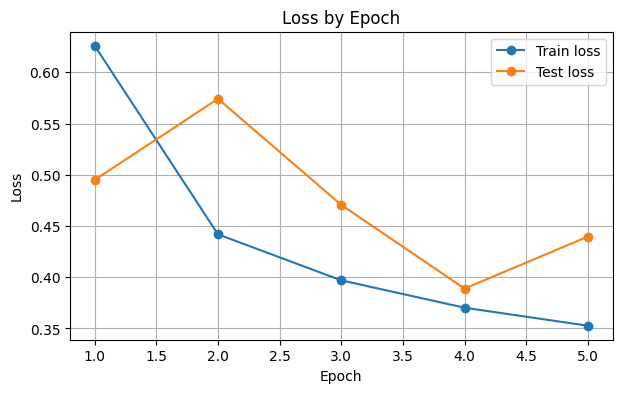

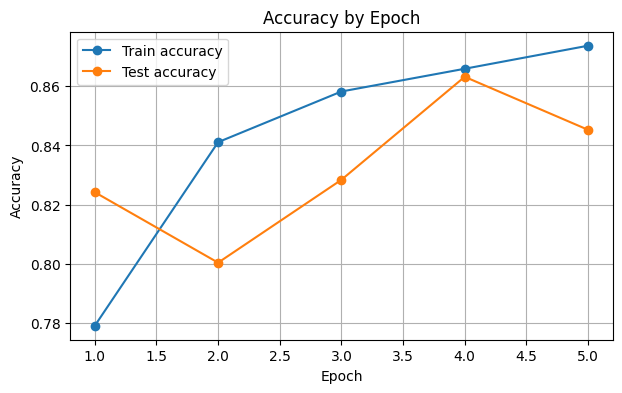

In [8]:
# Plot loss and accuracy curves
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs, history["test_loss"], marker="o", label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss by Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(epochs, history["test_accuracy"], marker="o", label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy by Epoch")
plt.legend()
plt.grid(True)
plt.show()

7. Inspect sample predictions

A prediction is the class with the highest logit. We'll compare the model's predicted label with the true label for a few test images.

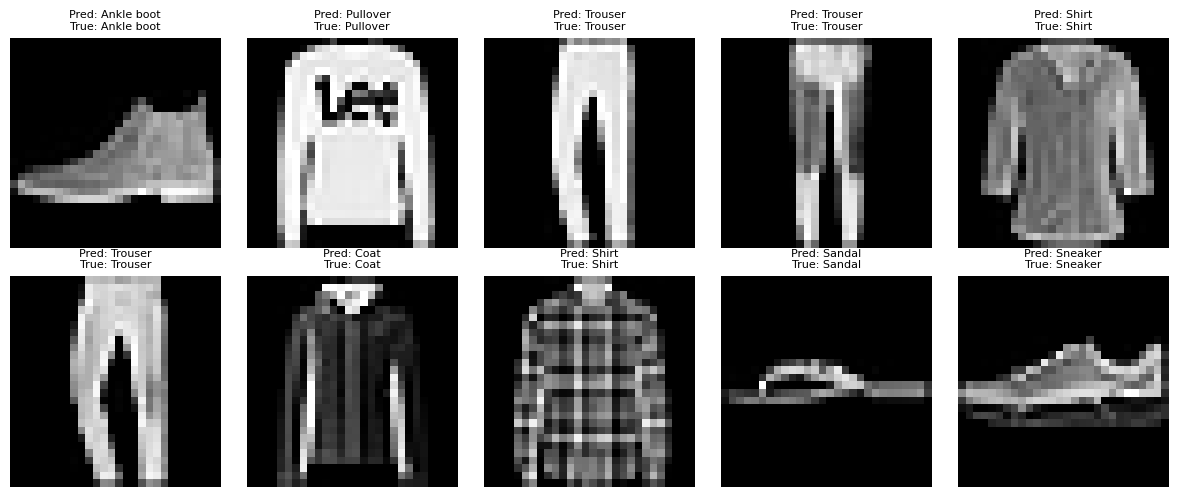

In [9]:
model.eval()
sample_images, sample_labels = next(iter(test_loader))
with torch.no_grad():
    sample_logits = model(sample_images.to(device))
    sample_predictions = sample_logits.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_images[i].squeeze(), cmap="gray")
    pred_name = class_names[sample_predictions[i].item()]
    true_name = class_names[sample_labels[i].item()]
    ax.set_title(f"Pred: {pred_name}\nTrue: {true_name}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

8. Exercises

**Exercise 1 — Explain the loop:** In your own words, explain what `optimizer.zero_grad()`, `loss.backward()`, and `optimizer.step()` each do.

**Exercise 2 — Change the learning rate:** Change `LEARNING_RATE` from `0.1` to `0.01`, recreate the model and optimizer, then train again. Compare the loss and accuracy curves. (Re-run the model-definition, loss/optimizer, training, and plotting cells in order.)

**Exercise 3 — Add a hidden layer:** Modify `FashionMLP` to use `784 → 128 → 64 → 10`, with ReLU after the first two linear layers. Recreate and train the model.

**Exercise 4 — Calculate accuracy:** Use the final `history["test_accuracy"][-1]` value and report it as a percentage.

**Exercise 5 — Reflect:** If training accuracy improves but test accuracy stops improving or falls, what might that suggest?

### Answers

1. `optimizer.zero_grad()` clears gradients from the previous batch; `loss.backward()` computes gradients of the loss with respect to trainable parameters; `optimizer.step()` updates parameters using those gradients.
2. A smaller learning rate usually makes updates smaller and can slow learning; actual accuracy depends on training and random variation. Compare the printed results rather than assuming a fixed score.
3. Use `nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))` after `nn.Flatten()`.
4. `print(f"Final test accuracy: {history['test_accuracy'][-1]:.2%}")`
5. It may indicate overfitting: the model is fitting the training examples better but not generalizing as well to unseen data.

In [10]:
# Exercise 4 — report final test accuracy
print(f"Final test accuracy: {history['test_accuracy'][-1]:.2%}")

Final test accuracy: 84.53%


9. Day 3 summary

I implemented the main supervised-learning training loop:
- Load data in batches with `DataLoader`
- Define a model by subclassing `nn.Module`
- Produce logits in the forward pass
- Calculate classification loss
- Clear gradients, backpropagate, and update parameters
- Evaluate without gradient tracking
- Plot loss and accuracy and inspect predictions
